# 豆瓣电影评论数据集 EDA

> 依据 `docs/01-eda-plan.md` 组织，共 0~7 章：数据加载与前置处理、数据质量、目标变量 RATING、文本基本特征、时间维度、用户维度、电影维度交叉分析、文本内容分析。

| 数据文件 | 规模 | 编码 |
|---|---|---|
| `dataset/comments.csv` | 约 42.4 万条评论 | UTF-8 |
| `dataset/movies.csv` | 约 9373 部电影 | **GBK** |

最终目标是为「评论打分模型」（见 `docs/02-rating-model-plan.md`）提供数据依据，第 9 节小结直接回答建模方案的 5 个前置问题。

In [1]:
import re
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.unicode.east_asian_width', True)

BASE = Path.cwd()
DATA = BASE / 'dataset'
OUT = BASE / 'output'
OUT.mkdir(exist_ok=True)

# 中文字体（macOS 常见字体逐个尝试）
_candidates = ['PingFang SC', 'Hiragino Sans GB', 'Arial Unicode MS', 'STHeiti', 'Heiti TC', 'SimHei']
_available = {f.name for f in font_manager.fontManager.ttflist}
_zh_font = next((f for f in _candidates if f in _available), None)
if _zh_font:
    plt.rcParams['font.sans-serif'] = [_zh_font, 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
print('中文字体:', _zh_font)

中文字体: Hiragino Sans GB


## 0. 数据加载与前置处理

- movies.csv 用 `gbk` 读取（失败则回退 `gb18030`）；comments.csv 用 UTF-8；
- 以 `MOVIEID = ID` 做 left join 补上电影名；
- 统一剔除：RATING 为空/超出 [1,5]、CONTENT 为空、MOVIEID 无法匹配电影的记录。

In [2]:
comments = pd.read_csv(DATA / 'comments.csv', encoding='utf-8')
try:
    movies = pd.read_csv(DATA / 'movies.csv', encoding='gbk', usecols=['ID', 'NAME'])
except UnicodeDecodeError:
    movies = pd.read_csv(DATA / 'movies.csv', encoding='gb18030', usecols=['ID', 'NAME'])

print('comments:', comments.shape)
print('movies:', movies.shape)
comments.head()

comments: (405083, 7)
movies: (9372, 2)


,ID,TIME,MOVIEID,RATING,CONTENT,CREATOR,ADD_TIME
0,4264,2015/6/10 2:45,10440138,1.0,弱到爆…剧情、氛围烘托、表演、服化道、特效，统统弱到爆！女主和哥哥转折超级无力，给女主默默烫发来表现阶段性转折也是醉了…，除了小迅猛龙看起来像狗以外，其余真是…吐槽无力...,身似,2018/1/5 15:05
1,4265,2015/6/10 10:39,10440138,2.0,傻逼电影，看在怀旧的份儿上两星半不能更多了……一蟹不如一蟹呀,Ent,2018/1/5 15:05
2,4266,2015/6/10 19:33,10440138,2.0,这片存在的意义难道就是告诉我们22年过去了，人类连在商业片方面都处于停滞不前，甚至倒退的状况？无论是气氛渲染、场面调度的表现还是人文关怀、人性冲突的体现都比不上22年前的《侏罗纪公园》。《侏罗纪公园》是经典名作，而《侏罗纪世界》只会...,有意识的贱民,2018/1/5 15:05
3,4267,2015/6/10 13:22,10440138,1.0,史诗级暴虐烂片。,亿万露电,2018/1/5 15:05
4,4268,2015/6/16 14:01,10440138,1.0,什么jb玩意儿。。。。。。如此反智。今时今日。,Marni,2018/1/5 15:05


In [3]:
# 关键修复：MOVIEID 被读成字符串、movies.ID 是 int64，必须先统一 key 类型再 join
comments = comments.copy()
comments['MOVIEID'] = pd.to_numeric(comments['MOVIEID'], errors='coerce').astype('Int64')
movies['ID'] = pd.to_numeric(movies['ID'], errors='coerce').astype('Int64')

df = comments.merge(movies, left_on='MOVIEID', right_on='ID', how='left', suffixes=('', '_movie'))
n0 = len(df)

rating_num = pd.to_numeric(df['RATING'], errors='coerce')
mask = (
    rating_num.between(1, 5)
    & df['CONTENT'].notna()
    & (df['CONTENT'].astype(str).str.strip() != '')
    & df['NAME'].notna()
)
df = df[mask].copy()
df['RATING'] = df['RATING'].astype(int)  # 先过滤掉 NaN/越界值，再安全转 int
print(f'原始 {n0} 条 -> 清洗后 {len(df)} 条（剔除 {n0 - len(df)} 条）')

df['TIME_DT'] = pd.to_datetime(df['TIME'], format='%Y/%m/%d %H:%M', errors='coerce')
df['YEAR'] = df['TIME_DT'].dt.year
df['LEN'] = df['CONTENT'].astype(str).str.len()
df[['ID', 'TIME', 'NAME', 'RATING', 'CONTENT', 'CREATOR']].head()

原始 405863 条 -> 清洗后 298385 条（剔除 107478 条）


,ID,TIME,NAME,RATING,CONTENT,CREATOR
0,4264,2015/6/10 2:45,侏罗纪世界,1,弱到爆…剧情、氛围烘托、表演、服化道、特效，统统弱到爆！女主和哥哥转折超级无力，给女主默默烫发来表现阶段性转折也是醉了…，除了小迅猛龙看起来像狗以外，其余真是…吐槽无力...,身似
1,4265,2015/6/10 10:39,侏罗纪世界,2,傻逼电影，看在怀旧的份儿上两星半不能更多了……一蟹不如一蟹呀,Ent
2,4266,2015/6/10 19:33,侏罗纪世界,2,这片存在的意义难道就是告诉我们22年过去了，人类连在商业片方面都处于停滞不前，甚至倒退的状况？无论是气氛渲染、场面调度的表现还是人文关怀、人性冲突的体现都比不上22年前的《侏罗纪公园》。《侏罗纪公园》是经典名作，而《侏罗纪世界》只会...,有意识的贱民
3,4267,2015/6/10 13:22,侏罗纪世界,1,史诗级暴虐烂片。,亿万露电
4,4268,2015/6/16 14:01,侏罗纪世界,1,什么jb玩意儿。。。。。。如此反智。今时今日。,Marni


## 1. 数据质量检查

### 1.1 缺失值与异常值
- RATING、CONTENT 的缺失率直接决定建模可用样本量；
- ADD_TIME 若几乎相同 → 一次性爬取快照，时间分析只用 TIME；
- 检查 RATING 是否有 0、6、小数等异常值。

,缺失数,缺失率%
ID,11,0.003
TIME,54,0.013
MOVIEID,111,0.027
RATING,111,0.027
CONTENT,141,0.035
CREATOR,691,0.171
ADD_TIME,168,0.041


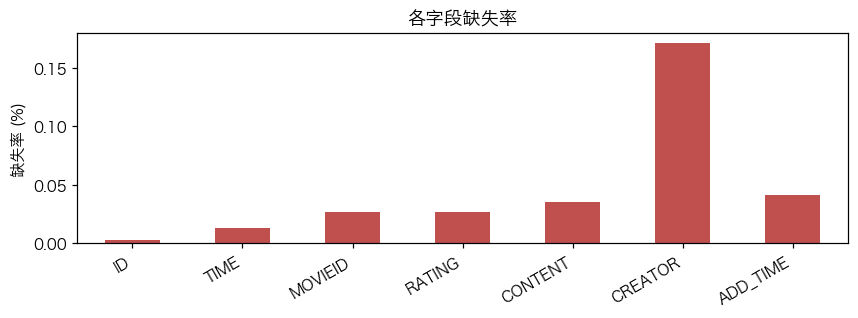

In [4]:
miss = pd.DataFrame({
    '缺失数': comments.isna().sum(),
    '缺失率%': (comments.isna().mean() * 100).round(3),
})
display(miss)

ax = miss['缺失率%'].plot(kind='bar', figsize=(8, 3), color='#c0504d', legend=False)
ax.set_title('各字段缺失率')
ax.set_ylabel('缺失率 (%)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [5]:
r = pd.to_numeric(comments['RATING'], errors='coerce')
print('RATING 取值分布（含 NaN）:')
print(r.value_counts(dropna=False).sort_index())
print()
print('是否存在非整数评分:', bool(((r.dropna() % 1) != 0).any()))
print('ADD_TIME 唯一值个数:', comments['ADD_TIME'].nunique(dropna=False))
print(comments['ADD_TIME'].value_counts().head(3))

RATING 取值分布（含 NaN）:
RATING
1.0     36967
2.0    140747
3.0      3029
4.0    135940
5.0     87263
NaN      1137
Name: count, dtype: int64

是否存在非整数评分: False
ADD_TIME 唯一值个数: 1572
ADD_TIME
2018/1/23 21:19    860
2018/1/23 21:23    860
2018/1/23 21:24    840
Name: count, dtype: int64


### 1.2 重复数据
- 完全重复行、`(CREATOR, MOVIEID)` 重复对、`CONTENT` 重复条数；
- 大量相同短文本（如「好片」）说明语料低信息量评论多，影响模型信号。

In [6]:
dup_stats = pd.Series({
    '完全重复行': int(comments.duplicated().sum()),
    '(CREATOR, MOVIEID) 重复': int(comments.duplicated(subset=['CREATOR', 'MOVIEID']).sum()),
    'CONTENT 重复': int(comments.duplicated(subset=['CONTENT']).sum()),
}, name='条数').to_frame()
display(dup_stats)

print('重复次数最多的 5 条评论文本:')
print(comments['CONTENT'].value_counts().head(5))

,条数
完全重复行,11
"(CREATOR, MOVIEID) 重复",22450
CONTENT 重复,34828


重复次数最多的 5 条评论文本:
CONTENT
无聊        367
不喜欢      319
一般        268
不好看      268
看不下去    197
Name: count, dtype: int64


## 2. 目标变量分布：RATING

### 2.1 评分分布
- 豆瓣评论典型呈 **J 型分布**（1 星与 5 星远多于中间分）→ 存在选择偏差：模型学的是「写评论的人」的评分；
- 类别不平衡程度决定是否需要重采样 / 类别权重；
- 中间档（3 星）若最少，提示 2/3/4 星区分是模型最难的部分。

,条数,占比%
RATING,,
1,27468,9.21
2,103421,34.66
3,30,0.01
4,100724,33.76
5,66742,22.37


均值 3.254 | 中位数 4.0 | 众数 2.0


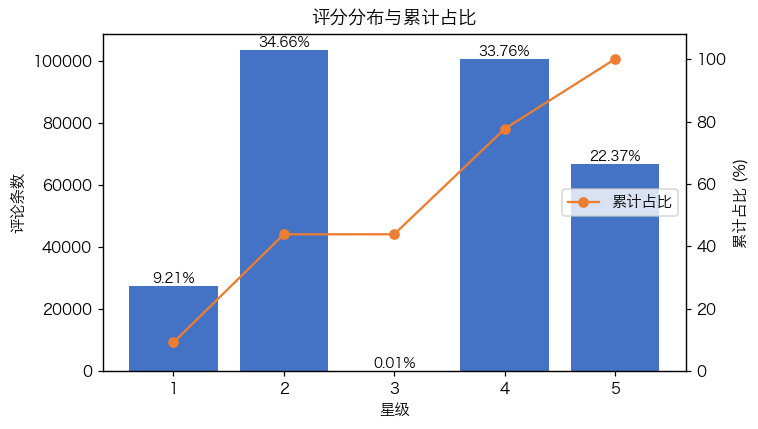

In [7]:
vc = df['RATING'].value_counts().sort_index()
pct = (vc / len(df) * 100).round(2)
display(pd.DataFrame({'条数': vc, '占比%': pct}))
print(f"均值 {df['RATING'].mean():.3f} | 中位数 {df['RATING'].median():.1f} | 众数 {df['RATING'].mode()[0]:.1f}")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(vc.index.astype(str), vc.values, color='#4472c4')
for b, p in zip(bars, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f'{p}%', ha='center', va='bottom', fontsize=9)
ax2 = ax.twinx()
cum = vc.cumsum() / len(df) * 100
ax2.plot(vc.index.astype(str), cum.values, color='#ed7d31', marker='o', label='累计占比')
ax2.set_ylabel('累计占比 (%)')
ax2.set_ylim(0, 108)
ax2.legend(loc='center right')
ax.set_title('评分分布与累计占比')
ax.set_xlabel('星级')
ax.set_ylabel('评论条数')
plt.tight_layout()
plt.show()

### 2.2 每部电影的整体评分水平
- 电影平均分集中区间、方差大的电影（两极分化）有哪些；
- 评论量的**长尾分布**意味着大部分电影只有几十条评论，「按电影聚合」的特征对长尾电影不可靠。

,n,mean,median,std
count,639.000,639.000,639.000,639.000
mean,466.956,3.315,3.393,1.239
std,221.331,0.477,0.640,0.272
min,40.000,1.700,2.000,0.337
25%,360.000,3.050,3.000,1.205
50%,440.000,3.148,3.000,1.297
75%,440.000,3.542,4.000,1.397
max,1780.000,4.673,5.000,1.723


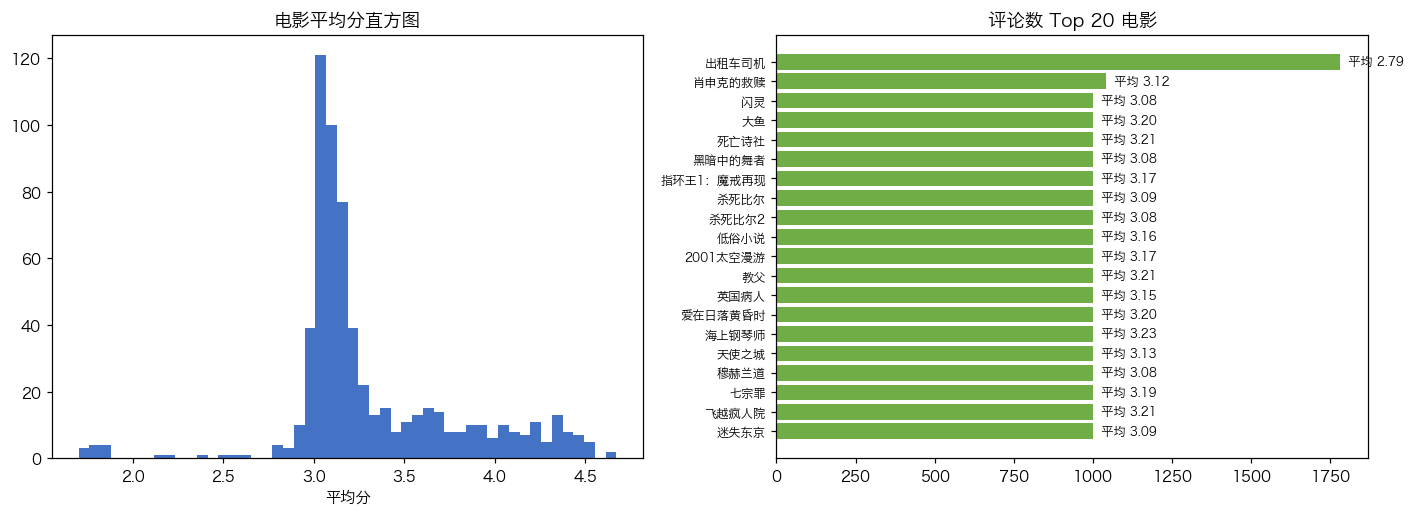

In [8]:
movie_stats = (df.groupby(['MOVIEID', 'NAME'])['RATING']
               .agg(n='count', mean='mean', median='median', std='std')
               .reset_index())
display(movie_stats[['n', 'mean', 'median', 'std']].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].hist(movie_stats['mean'].dropna(), bins=50, color='#4472c4')
axes[0].set_title('电影平均分直方图')
axes[0].set_xlabel('平均分')

top20 = movie_stats.nlargest(20, 'n').sort_values('n')
axes[1].barh(top20['NAME'], top20['n'], color='#70ad47')
for i, (n, m) in enumerate(zip(top20['n'], top20['mean'])):
    axes[1].text(n, i, f'  平均 {m:.2f}', va='center', fontsize=8)
axes[1].set_title('评论数 Top 20 电影')
axes[1].tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

## 3. 文本基本特征分布：CONTENT

### 3.1 评论长度分布
- 短评（<20 字）占比高是豆瓣短评的典型特征，超短文本对文本模型几乎没有信号；
- 对比各星级长度：长度本身可能有预测力，可作为辅助特征。

count    298385.0
mean         42.8
std          41.6
min           1.0
50%          27.0
90%         110.0
99%         149.0
max        4244.0
超短评论(<20字)占比: 38.3%


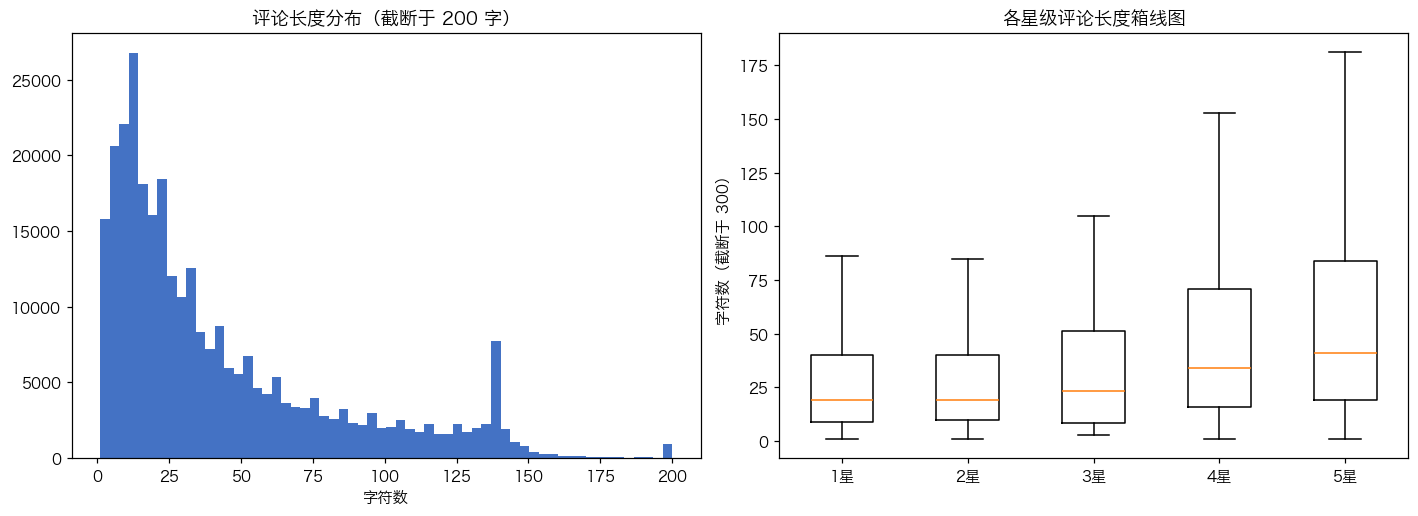

In [9]:
print(df['LEN'].describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_string())
print(f"超短评论(<20字)占比: {(df['LEN'] < 20).mean() * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].hist(df['LEN'].clip(upper=200), bins=60, color='#4472c4')
axes[0].set_title('评论长度分布（截断于 200 字）')
axes[0].set_xlabel('字符数')

data_by = [df.loc[df['RATING'] == k, 'LEN'].clip(upper=300) for k in range(1, 6)]
axes[1].boxplot(data_by, labels=[f'{k}星' for k in range(1, 6)], showfliers=False)
axes[1].set_title('各星级评论长度箱线图')
axes[1].set_ylabel('字符数（截断于 300）')
plt.tight_layout()
plt.show()

### 3.2 文本内容质量
- 检查 emoji、纯英文、URL、@用户、HTML 转义符、「剧透」字样的占比 → 决定清洗规则；
- 抽样阅读各星级评论，为「分星级词云」建立直觉。

In [10]:
s = df['CONTENT'].astype(str)
quality = pd.Series({
    '含 emoji/表情': s.str.contains(r'[\U0001F000-\U0001FAFF\u2600-\u27BF]', regex=True).mean() * 100,
    '纯英文': s.str.fullmatch(r"[A-Za-z0-9\s!?.,'\"-]*").mean() * 100,
    '含 URL': s.str.contains(r'(https?://|www\.)', regex=True).mean() * 100,
    '含 @用户': s.str.contains('@').mean() * 100,
    '含 HTML 转义符': s.str.contains(r'&\w+;', regex=True).mean() * 100,
    "含'剧透'字样": s.str.contains('剧透').mean() * 100,
}, name='占比%').round(3).to_frame()
display(quality)

print('各星级随机抽样（每星级 4 条）:')
for k in range(1, 6):
    print(f'—— {k} 星 ——')
    texts = df.loc[df['RATING'] == k, 'CONTENT'].drop_duplicates()
    for t in texts.sample(min(4, len(texts)), random_state=42):
        print('  •', str(t)[:80].replace('\n', ' '))
    print()

,占比%
含 emoji/表情,0.261
纯英文,3.053
含 URL,0.193
含 @用户,0.277
含 HTML 转义符,0.001
含'剧透'字样,0.172


各星级随机抽样（每星级 4 条）:
—— 1 星 ——
  • 这部片子真的太老了，回头看08年的豆瓣，一个胖妞的影评是说自己虽然微胖仍有3追求者，底下还有很多正能量的朋友说加油哦，你棒棒哒，要是放到2015，大家估计会说两
  • 介最佳可欣赏不起了。
  • 不知道想说什么，这部电影
  • 不喜欢这种态度

—— 2 星 ——
  • 最后结局俗掉
  • 男主太猥琐了！！！！
  • 冲着Monica才看的，结果是烂片
  • 不知道吴清源故事的人看了片子之后同样不知道他的故事

—— 3 星 ——
  • 支持国产。
  • 第一次见识这个故事。终于知道《东方快车》为什么经久不衰了！厉害！前半段枯燥，当人物的境遇都呈现出来后，非常吸引人！
  • 沿袭第一部的套路
  • 对不断重复的故事真的爱不起来，头好晕，还有…女主真丑死。

—— 4 星 ——
  • when a man love a woman,but the man who is a death
  • sad
  • TED的演讲貌似更震撼人心。。！
  • 確實是前無古人的推理傑作。小時候模糊的印象全回來了，對，就是芬尼那個頭可斷毛型不可亂的波洛，一個精緻考究的矮胖子。PS大家都只看英格麗褒曼嗎？勞倫白考爾超美啊。

—— 5 星 ——
  • 最后一部  但是前两部的场景历历在目  虽然这部不在是宿醉   不过对于结局篇还是让人感动
  • 广元静静的走上讲台，写下一段英文，大致的意思是“人生得意须尽欢”。懂？
  • 湿了。几位颜色先生太有范儿了。我果然是十足直女，见着几个身着黑色西装戴墨镜的男人横行霸道口水流一地。
  • lilico真的很美啊 一出场惊艳了 和妹妹在草坪见面 还有穿蓝色裙子在水里 美！爆！了！ 还有，女生的叽叽喳喳真 讨 厌。



## 4. 时间维度分布

### 4.1 评论的时间趋势
- 评论通常集中在电影上映后 1~3 个月内；
- 对比好评/差评随时间的走势，观察「高开低走」的口碑反转。

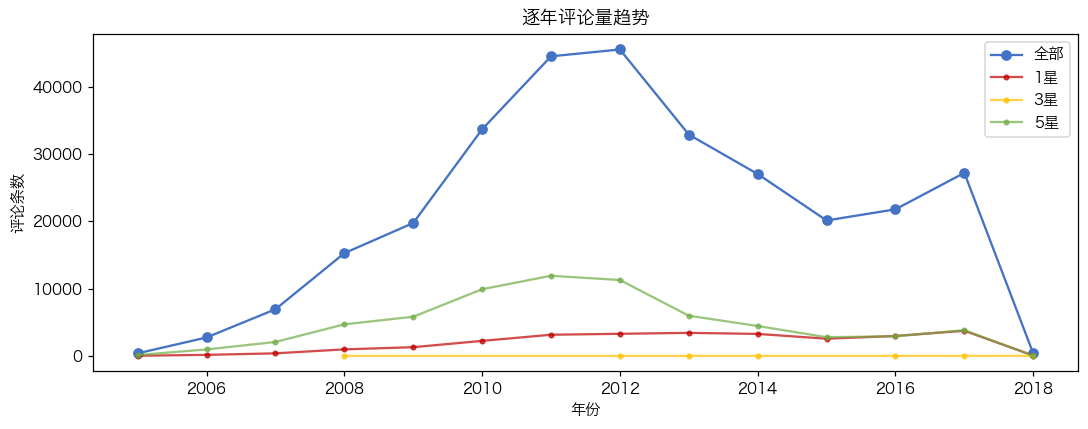

YEAR,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
评论数,380,2740,6939,15275,19764,33698,44550,45566,32915,27047,20138,21794,27217,362


In [11]:
by_year = df.groupby('YEAR').size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_year.index, by_year.values, marker='o', color='#4472c4', label='全部')
for k, c in [(1, '#c00000'), (3, '#ffc000'), (5, '#70ad47')]:
    sub = df[df['RATING'] == k].groupby('YEAR').size()
    ax.plot(sub.index, sub.values, marker='.', alpha=0.7, color=c, label=f'{k}星')
ax.set_title('逐年评论量趋势')
ax.set_xlabel('年份')
ax.set_ylabel('评论条数')
ax.legend()
plt.tight_layout()
plt.show()
by_year.to_frame('评论数').T

### 4.2 评分与评论时间的关系
- 早期 vs 晚期评论的星级分布差异，反映口碑演化；
- 若不同年份星级占比系统性漂移，说明存在**时间混杂因素**，建模时要做按时间切分的验证。

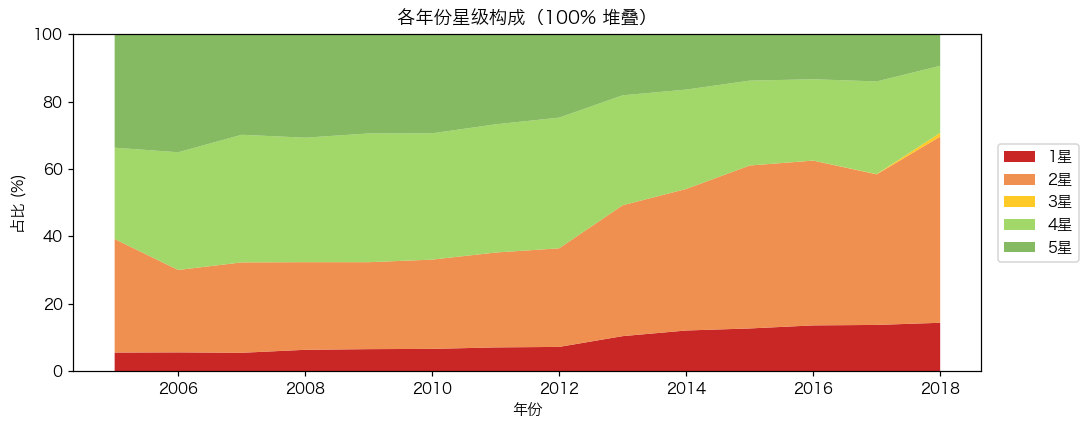

RATING,1,2,3,4,5
YEAR,,,,,
2005,5.5,33.7,0.0,27.1,33.7
2006,5.6,24.5,0.0,34.9,35.0
2007,5.5,26.8,0.0,37.9,29.8
2008,6.3,26.0,0.0,36.9,30.7
2009,6.5,25.8,0.0,38.2,29.5
2010,6.6,26.5,0.0,37.5,29.4
2011,7.1,28.2,0.0,38.0,26.7
2012,7.2,29.3,0.0,38.8,24.8
2013,10.4,38.8,0.0,32.6,18.1


In [12]:
share = (df.pivot_table(index='YEAR', columns='RATING', values='ID', aggfunc='count', fill_value=0)
         .reindex(columns=range(1, 6), fill_value=0))  # 缺失的星级列补 0
share = share.div(share.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.stackplot(share.index,
             [share[c] for c in range(1, 6)],
             labels=[f'{k}星' for k in range(1, 6)],
             colors=['#c00000', '#ed7d31', '#ffc000', '#92d050', '#70ad47'], alpha=0.85)
ax.set_title('各年份星级构成（100% 堆叠）')
ax.set_xlabel('年份')
ax.set_ylabel('占比 (%)')
ax.set_ylim(0, 100)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()
share.round(1)

## 5. 用户维度分布
- 评论数分布是否呈幂律/长尾，头部是否异常突出（刷评论机器人嫌疑）；
- 头部活跃用户评分习惯偏严/偏松 → 同一用户内评分方差与整体方差对比；
- 若刷号明显，数据清洗时要剔除。

用户数: 75203
count    75203.00
mean         3.96
std         13.81
min          1.00
25%          1.00
50%          1.00
75%          3.00
max       2989.00
仅评论 1 条的用户占比: 52.5%


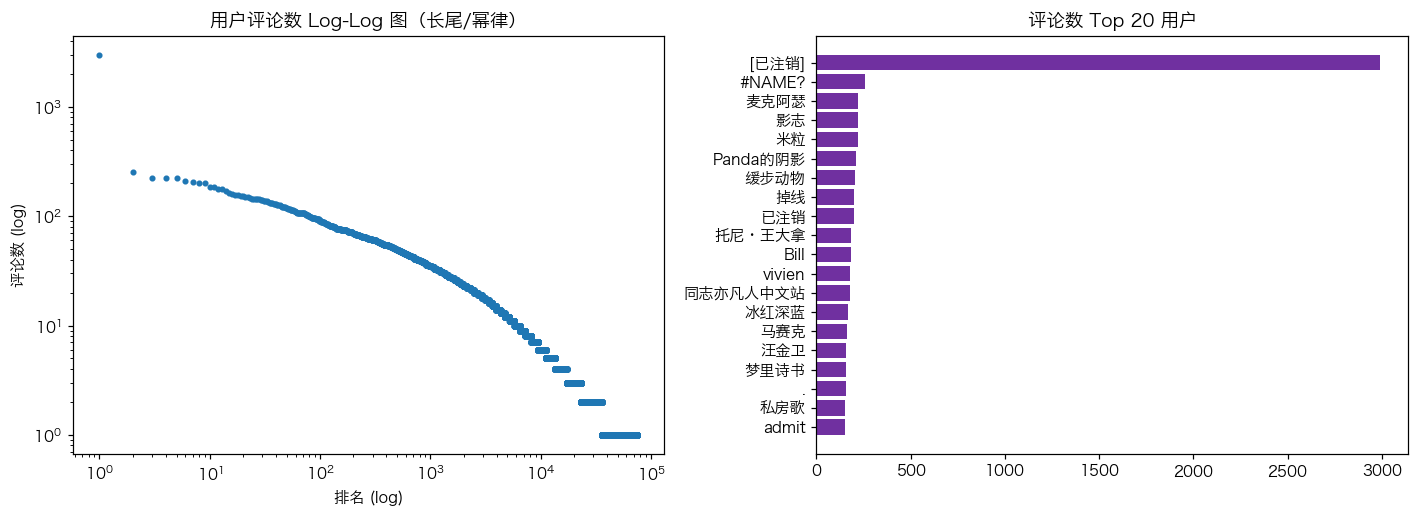

头部活跃用户的评分习惯:


,mean,std,count
CREATOR,,,
[已注销],3.37,1.39,2989
#NAME?,3.39,1.32,256
麦克阿瑟,4.33,0.53,223
影志,4.18,0.87,222
米粒,4.35,0.65,222
Panda的阴影,4.03,0.80,209
缓步动物,4.32,0.55,204
已注销,3.08,1.41,202
掉线,4.04,1.04,202


整体平均分 3.25 | 整体标准差 1.37


In [13]:
user_counts = df['CREATOR'].value_counts()
print('用户数:', user_counts.size)
print(user_counts.describe().round(2).to_string())
print(f"仅评论 1 条的用户占比: {(user_counts == 1).mean() * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].loglog(np.arange(1, len(user_counts) + 1), user_counts.values, '.')
axes[0].set_title('用户评论数 Log-Log 图（长尾/幂律）')
axes[0].set_xlabel('排名 (log)')
axes[0].set_ylabel('评论数 (log)')

top_u = user_counts.head(20).sort_values()
axes[1].barh(top_u.index.astype(str), top_u.values, color='#7030a0')
axes[1].set_title('评论数 Top 20 用户')
plt.tight_layout()
plt.show()

print('头部活跃用户的评分习惯:')
top_users = user_counts.head(20).index
strict = (df[df['CREATOR'].isin(top_users)].groupby('CREATOR')['RATING']
          .agg(['mean', 'std', 'count']).round(2)
          .sort_values('count', ascending=False))
display(strict)
print(f"整体平均分 {df['RATING'].mean():.2f} | 整体标准差 {df['RATING'].std():.2f}")

## 6. 电影维度交叉分析

### 6.1 电影 × 评分
- 堆叠条形图直观看到哪部电影两极分化（1 星和 5 星同时高）、哪部一边倒；
- 散点图：样本少的电影平均分波动更大（回归到均值）。

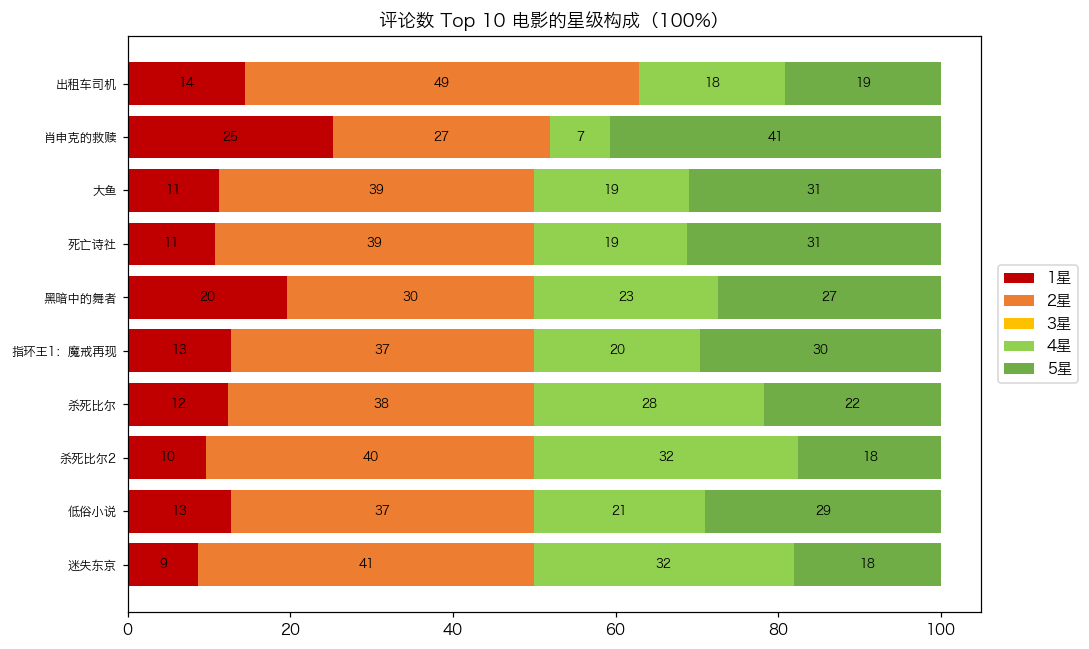

RATING,1,2,3,4,5
NAME,,,,,
出租车司机,14.4,48.5,0.0,17.9,19.2
肖申克的救赎,25.3,26.6,0.0,7.4,40.7
大鱼,11.2,38.8,0.0,19.0,31.0
死亡诗社,10.7,39.3,0.0,18.8,31.2
黑暗中的舞者,19.6,30.4,0.0,22.6,27.4
指环王1：魔戒再现,12.7,37.3,0.0,20.4,29.6
杀死比尔,12.4,37.6,0.0,28.2,21.8
杀死比尔2,9.7,40.3,0.0,32.5,17.5
低俗小说,12.7,37.3,0.0,21.0,29.0


In [14]:
top10 = movie_stats.nlargest(10, 'n')
comp = (df[df['MOVIEID'].isin(top10['MOVIEID'])]
        .pivot_table(index='NAME', columns='RATING', values='ID', aggfunc='count', fill_value=0)
        .reindex(columns=range(1, 6), fill_value=0)  # 3星极少量：缺失的星级列补 0
        .loc[top10['NAME']])
comp_pct = comp.div(comp.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 6))
left = np.zeros(len(comp_pct))
colors5 = ['#c00000', '#ed7d31', '#ffc000', '#92d050', '#70ad47']
for k, c in zip(range(1, 6), colors5):
    vals = comp_pct[k].values
    ax.barh(comp_pct.index, vals, left=left, color=c, label=f'{k}星')
    for i, v in enumerate(vals):
        if v > 6:
            ax.text(left[i] + v / 2, i, f'{v:.0f}', ha='center', va='center', fontsize=8)
    left += vals
ax.set_title('评论数 Top 10 电影的星级构成（100%）')
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
ax.invert_yaxis()
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()
comp_pct.round(1)

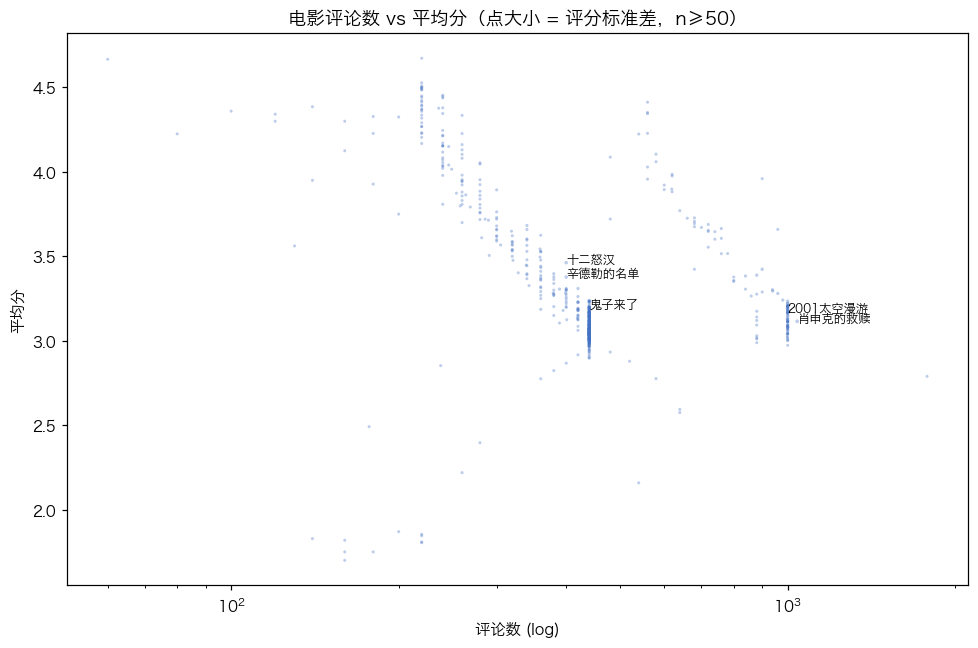

评论数与平均分的相关性（Spearman）: -0.417


In [15]:
ms = movie_stats[movie_stats['n'] >= 50].copy()  # 过滤小样本电影
fig, ax = plt.subplots(figsize=(9, 6))
sizes = np.clip(ms['std'].fillna(0) ** 2 * 2, 4, 400)
ax.scatter(ms['n'], ms['mean'], s=sizes, alpha=0.35, color='#4472c4', edgecolors='none')
ax.set_xscale('log')
ax.set_title('电影评论数 vs 平均分（点大小 = 评分标准差，n≥50）')
ax.set_xlabel('评论数 (log)')
ax.set_ylabel('平均分')
for _, r_ in ms.nlargest(5, 'std').iterrows():  # 标注最两极分化的 5 部
    ax.annotate(str(r_['NAME'])[:12], (r_['n'], r_['mean']), fontsize=8)
plt.tight_layout()
plt.show()
print(f"评论数与平均分的相关性（Spearman）: {ms[['n', 'mean']].corr(method='spearman').iloc[0, 1]:.3f}")

### 6.2 星级 × 评论长度的热力图
长度与星级是否相关、交互关系如何，为模型特征工程提供依据。

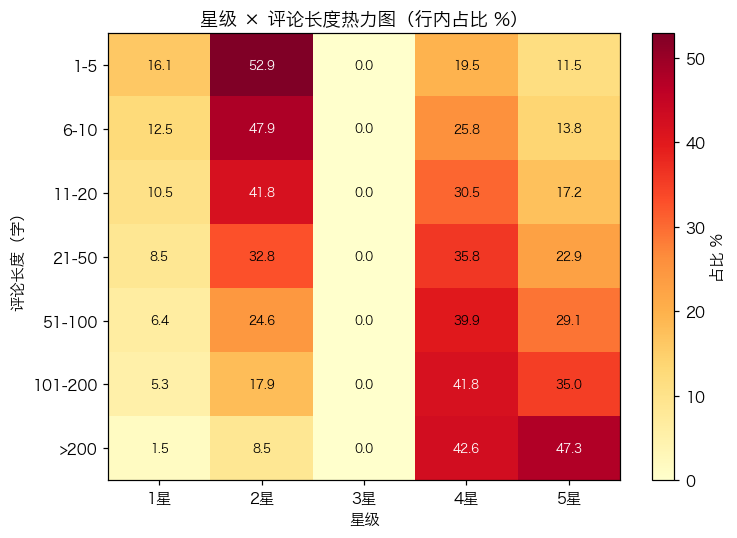

In [16]:
bins = [0, 5, 10, 20, 50, 100, 200, 10_000]
labels = ['1-5', '6-10', '11-20', '21-50', '51-100', '101-200', '>200']
df['LEN_BUCKET'] = pd.cut(df['LEN'], bins=bins, labels=labels)
hm = (df.pivot_table(index='LEN_BUCKET', columns='RATING', values='ID',
                     aggfunc='count', fill_value=0, observed=False)
      .reindex(columns=range(1, 6), fill_value=0))  # 缺失的星级列补 0
hm_pct = hm.div(hm.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(hm_pct.values, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(5))
ax.set_xticklabels([f'{k}星' for k in range(1, 6)])
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
for i in range(hm_pct.shape[0]):
    for j in range(5):
        v = hm_pct.values[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=8,
                color='white' if v > 40 else 'black')
ax.set_title('星级 × 评论长度热力图（行内占比 %）')
ax.set_xlabel('星级')
ax.set_ylabel('评论长度（字）')
fig.colorbar(im, ax=ax, label='占比 %')
plt.tight_layout()
plt.show()

## 7. 文本内容分析（面向打分模型的关键环节）

### 7.1 分星级高频词与区分词
- jieba 分词 + 停用词过滤，各星级 Top 30 高频词；
- 用 **log-odds ratio** 找「星级区分词」：若 1 星富集「烂/失望/垃圾」、5 星富集「经典/感动/神作」，则「文本可预测星级」的建模前提成立；
- 反讽/网络用语（「绝了」「细思极恐」）方向依赖上下文，是词袋模型的盲区。

In [17]:
try:
    import jieba
    HAS_JIEBA = True
except ImportError:
    HAS_JIEBA = False
    print('未安装 jieba（pip install jieba），退化为按字切分')

if HAS_JIEBA:
    df['TOKENS'] = df['CONTENT'].astype(str).map(
        lambda t: [w for w in jieba.lcut(t) if len(w) > 1])
else:
    df['TOKENS'] = df['CONTENT'].astype(str).map(lambda t: list(t))
print('分词示例:', df['TOKENS'].iloc[0][:12])

未安装 jieba（pip install jieba），退化为按字切分
分词示例: ['弱', '到', '爆', '…', '剧', '情', '、', '氛', '围', '烘', '托', '、']


In [18]:
STOPWORDS = set('''的 了 是 我 你 他 她 它 我们 你们 他们 这 那 也 都 就 不 没 有 在 和 与 但 而 被 让 给
一个 这个 那个 什么 还是 已经 就是 不是 觉得 感觉 真的 以及 因为 所以 如果 虽然 不过
电影 影片 片子 东西 时候 地方 出来 起来 自己 一部 这是 没有 可以 真是 怎么 为什么 这样 那样
啊 吧 吗 呢 哦 呀 嗯 很 太 更 最 挺 还 又 再 才 只 把 从 向 往 为 之 以 于 或 等 些'''.split())

star_words = {}
for k in range(1, 6):
    star_words[k] = Counter(
        w for toks in df.loc[df['RATING'] == k, 'TOKENS'] for w in toks
        if w not in STOPWORDS)

pd.DataFrame({f'{k}星': [f'{w} ({c})' for w, c in star_words[k].most_common(30)]
              for k in range(1, 6)})

,1星,2星,3星,4星,5星
0,， (32286),， (116151),， (50),， (183771),， (134263)
1,。 (21120),。 (87439),(28),。 (112122),(97906)
2,(13230),(50154),。 (19),(101762),。 (77596)
3,一 (12391),一 (43296),好 (16),一 (62143),一 (48276)
4,看 (11810),看 (42486),看 (14),人 (46422),e (43168)
5,！ (8116),人 (26619),一 (12),e (44265),人 (37223)
6,人 (7871),. (25337),人 (10),看 (39046),o (32252)
7,么 (7266),么 (24017),o (9),. (33443),a (29693)
8,个 (6798),个 (23180),i (9),个 (32857),t (28969)
9,片 (6796),好 (21653),得 (9),o (32381),看 (28749)


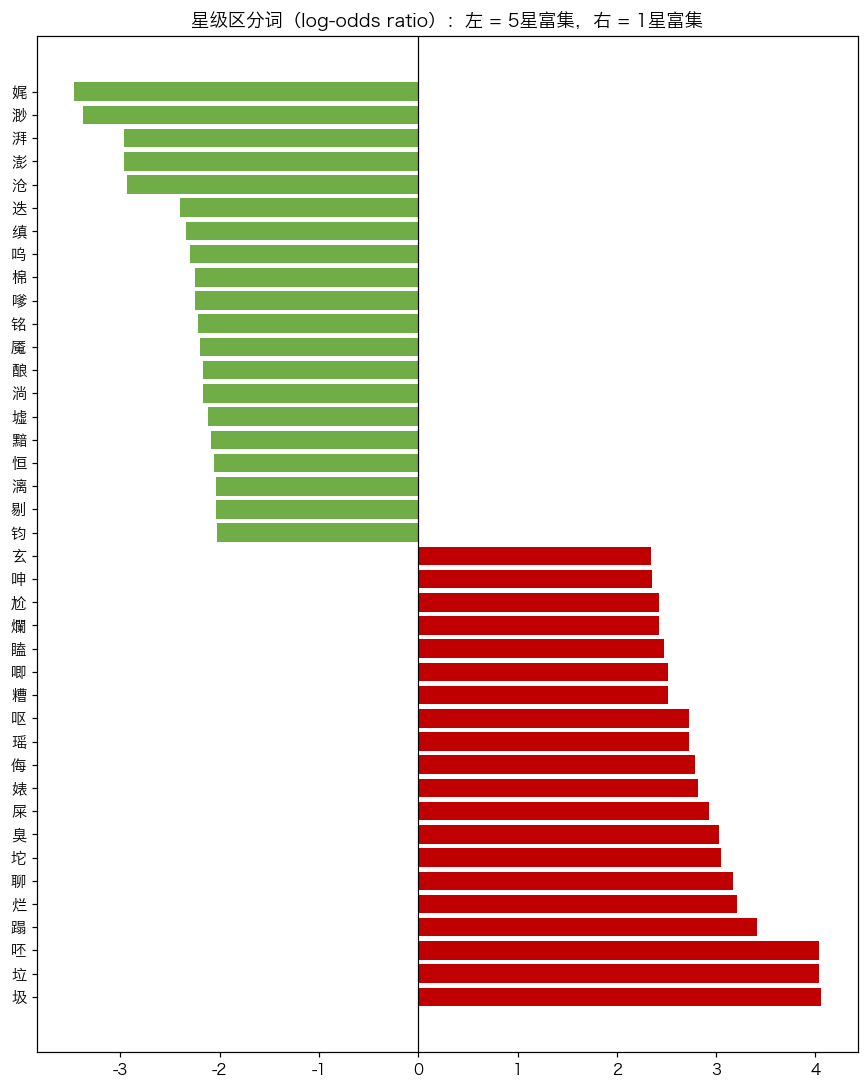

,1星频次,5星频次,log_odds
词,,,
圾,979,73,4.053456
垃,980,74,4.041053
呸,38,2,4.034918
蹋,55,7,3.415879
烂,2739,478,3.213981
聊,1537,279,3.173417
坨,91,18,3.047318
臭,246,51,3.028113
屎,396,91,2.932116


,1星频次,5星频次,log_odds
词,,,
娓,0,138,-3.464505
渺,0,126,-3.374218
湃,0,83,-2.960848
澎,0,83,-2.960848
沧,0,81,-2.936751
迭,1,95,-2.401232
缜,0,44,-2.336694
呜,8,388,-2.296386
棉,2,123,-2.251701


In [19]:
c1, c5 = star_words[1], star_words[5]
n1, n5 = sum(c1.values()), sum(c5.values())
alpha = 1.0
rows = []
for w in set(c1) | set(c5):
    f1, f5 = c1.get(w, 0), c5.get(w, 0)
    if f1 + f5 < 30:  # 过滤低频词
        continue
    p1 = (f1 + alpha) / (n1 + alpha)
    p5 = (f5 + alpha) / (n5 + alpha)
    rows.append((w, f1, f5, float(np.log(p1 / p5))))
lod_df = pd.DataFrame(rows, columns=['词', '1星频次', '5星频次', 'log_odds']).set_index('词')

both = pd.concat([lod_df.nlargest(20, 'log_odds'),          # 1 星富集（右）
                  lod_df.nsmallest(20, 'log_odds').iloc[::-1]])  # 5 星富集（左）
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(both.index, both['log_odds'],
        color=['#c00000' if v > 0 else '#70ad47' for v in both['log_odds']])
ax.axvline(0, color='black', lw=0.8)
ax.set_title('星级区分词（log-odds ratio）：左 = 5星富集，右 = 1星富集')
plt.tight_layout()
plt.show()
display(lod_df.nlargest(15, 'log_odds'))
display(lod_df.nsmallest(15, 'log_odds'))

In [20]:
FONT_CANDIDATES = [
    '/System/Library/Fonts/PingFang.ttc',
    '/System/Library/Fonts/Hiragino Sans GB.ttc',
    '/System/Library/Fonts/STHeiti Light.ttc',
    '/System/Library/Fonts/Supplemental/Arial Unicode.ttf',
]
font_path = next((p for p in FONT_CANDIDATES if Path(p).exists()), None)
try:
    from wordcloud import WordCloud
    assert font_path, '未找到中文字体文件，跳过词云'
    wc = WordCloud(font_path=font_path, width=600, height=360,
                   background_color='white', max_words=100)
    fig, axes = plt.subplots(1, 5, figsize=(20, 4.2))
    for k in range(1, 6):
        wc.generate_from_frequencies(dict(star_words[k].most_common(150)))
        axes[k - 1].imshow(wc.to_array(), interpolation='bilinear')
        axes[k - 1].set_title(f'{k}星')
        axes[k - 1].axis('off')
    plt.tight_layout()
    plt.show()
except Exception as e:
    print('跳过词云:', e)

跳过词云: No module named 'wordcloud'


### 7.2 N-gram 与句式
各星级 Top 20 二元组：词袋丢掉的搭配（「不 好看」vs「好看」）是否大量出现，决定是否需要保留否定结构。

In [21]:
bigrams = {}
for k in (1, 3, 5):
    cnt = Counter()
    for toks in df.loc[df['RATING'] == k, 'TOKENS']:
        cnt.update(zip(toks, toks[1:]))
    bigrams[k] = cnt

pd.DataFrame({
    f'{k}星': [f"{''.join(b)} ({c})" for b, c in bigrams[k].most_common(20)]
    for k in (1, 3, 5)
})

,1星,3星,5星
0,电影 (5214),.. (4),电影 (16113)
1,。。 (4465),了， (4),e (12425)
2,.. (3423),一个 (4),.. (10705)
3,！！ (3270),赫本 (4),。。 (9457)
4,什么 (3103),故事 (4),！！ (8732)
5,了， (2225),的， (3),一个 (8329)
6,一个 (2046),。\n (3),t (7440)
7,没有 (1921),d (3),th (6941)
8,就是 (1837),ou (3),t (6780)
9,了。 (1804),好看 (3),in (6658)


### 7.3 每部电影内部的文本-评分一致性
选 3 部口碑分化电影，对照其 1 星 vs 5 星评论原文——控制「电影本身分数」干扰后，文本信号是否存在的最直接证据。

In [22]:
polar = movie_stats[(movie_stats['n'] >= 200) & (movie_stats['std'] >= 1.2)].nlargest(3, 'std')
for _, m in polar.iterrows():
    print(f"===== {m['NAME']}（n={m['n']:.0f}，平均 {m['mean']:.2f}，标准差 {m['std']:.2f}）=====")
    for k in (1, 5):
        print(f'—— {k} 星示例 ——')
        texts = df.loc[(df['MOVIEID'] == m['MOVIEID']) & (df['RATING'] == k), 'CONTENT'].drop_duplicates()
        for t in texts.sample(min(5, len(texts)), random_state=1):
            print('  •', str(t)[:60].replace('\n', ' '))
    print()

===== 肖申克的救赎（n=1040，平均 3.12，标准差 1.72）=====
—— 1 星示例 ——
  • 很好看 确实很好看也很深刻 但看不惯中国网友大多数喜欢它而对'《Forrest gump》诋毁 希望有一天评分在9分左右
  • 呵呵，你们逼格真高，这电影好好哟 豆瓣果然是一群sb装x的恶心文艺青年
  • 不，我不喜欢这电影。
  • 烂片典范之一
  • 普普通通
—— 5 星示例 ——
  • 因为这样的经典，所以无法喜欢越狱；同时，这个故事教育我们说，有项专业技能是很重要的
  • 2008年11月28日，第一次看肖申克。那时候观影量还不到五百吧。给五星是见识浅。现在差不多九年过去，我在豆瓣标注看过的
  • 这是一部直敲心灵的  电影~  Hope Is A good thing，maybe the best thing in
  • 所谓造梦，大概就是这样，给人以希望与光明，令人感受到那一种震撼。
  • I hope I can make it across the border, I hope the Pacific i

===== 鬼子来了（n=440，平均 3.20，标准差 1.68）=====
—— 1 星示例 ——
  • 国产垃圾
  • 很好看，反应抗日战争时期的事情，看完很震撼。打五星，开头有裸露镜头扣四星。
  • 看不下去，所以太监了它，以后有机会再看吧。
  • 这就是中国农民视角的抗日片?
  • 垃圾低端下流搞笑片
—— 5 星示例 ——
  • 这无疑是中国抗战题材中与历史真实最接近、剖析民族劣根性最彻底、在上位者最不能容忍的最佳电影。姜文，你怎么可以这么深刻！！
  • 我认为，姜文所再现的战时场面和环境才是最真实的战时人民生活的场景，完完全全的再现了善良朴实的中国人，也展现了淳朴背后的无
  • 热闹的配乐，未开化的村庄，娓娓道来尽是荒唐事。姜文好才情，好视角，此片在堂堂天朝泱泱大国岂有不被禁之理。我磨刀霍霍向鬼神
  • 每分每秒的牛逼！
  • 95/100 对这片土地上的社会无情的嘲讽，没有一丝的怜悯和妥协，这是个不能和不敢说真话的时代，所以当一个剧本没有任何艺

===== 十二怒汉（n=400，平均 3.46，标准差 1.65）=====
—— 1 星示例 ——
  • 看得好难忍
  • 

## 8. 产出物

- 本 notebook：全部统计表与图表；
- `output/cleaned_comments.csv`：剔除缺失/异常/完全重复后的中间数据集，供建模直接使用；
- 每张图的具体分析结论见 notebook 运行结果与 `docs/eda-findings.md`（可基于本 notebook 结果撰写）。

## 9. EDA → 建模的关键结论对接
以下代码自动汇总回答方案第 9 节的 5 个问题。

In [23]:
clean = df.drop_duplicates(subset=['CREATOR', 'MOVIEID', 'CONTENT'], keep='last')
out_path = OUT / 'cleaned_comments.csv'
clean[['ID', 'TIME', 'MOVIEID', 'NAME', 'RATING', 'CONTENT', 'CREATOR', 'LEN']].to_csv(
    out_path, index=False, encoding='utf-8')
print(f'清洗后数据 {len(clean)} 条 -> {out_path}')

清洗后数据 284250 条 -> /Users/justin/Developer/ai-workspace/ai-aura-express-bootcamp-homeworks/homework-2026-11-14/douban-comments/output/cleaned_comments.csv


In [24]:
vcn = df['RATING'].value_counts(normalize=True).sort_index()
imb = vcn.max() / vcn.min()
short_pct = (df['LEN'] < 20).mean() * 100
dup_user_movie = int(df.duplicated(subset=['CREATOR', 'MOVIEID']).sum())

print('==== EDA -> 建模的关键结论（对应方案第 9 节） ====')
print('1. RATING 分布:', ' | '.join(f'{k}星 {vcn[k] * 100:.1f}%' for k in range(1, 6)))
print(f'   最大/最小星级占比比 = {imb:.1f} -> ' + ('建议类别权重/重采样' if imb > 2 else '不平衡程度可接受'))
print(f'2. 超短文本(<20字)占比 {short_pct:.1f}% -> ' + ('建议设最小长度过滤' if short_pct > 20 else '可不过滤'))
print('3. 区分词: 见 7.1 log-odds 图 —— 1/5 星富集词方向明确则词袋 baseline 可行')
print('4. 时间漂移: 见 4.2 各年份星级构成 —— 占比系统性漂移则验证集需按时间切分')
print(f'5. (CREATOR, MOVIEID) 重复 {dup_user_movie} 条、用户分布见第 5 节 -> 决定清洗规则')

==== EDA -> 建模的关键结论（对应方案第 9 节） ====
1. RATING 分布: 1星 9.2% | 2星 34.7% | 3星 0.0% | 4星 33.8% | 5星 22.4%
   最大/最小星级占比比 = 3447.4 -> 建议类别权重/重采样
2. 超短文本(<20字)占比 38.3% -> 建议设最小长度过滤
3. 区分词: 见 7.1 log-odds 图 —— 1/5 星富集词方向明确则词袋 baseline 可行
4. 时间漂移: 见 4.2 各年份星级构成 —— 占比系统性漂移则验证集需按时间切分
5. (CREATOR, MOVIEID) 重复 16987 条、用户分布见第 5 节 -> 决定清洗规则
